# Исследование `cal_h_bond_acceptor_count` и `cal_h_bond_donor_count`

Ноутбук выполняет раздел **«3. План анализа случайной величины»** из `data_review.ipynb` для выбранной там пары дискретных счётных характеристик:

- `cal_h_bond_acceptor_count` — число центров молекулы, способных **принимать** водородную связь (далее **A**);
- `cal_h_bond_donor_count` — число центров, способных **отдавать** водородную связь (далее **D**).

Этапы идут в том же порядке, что и в плане: 1) стохастическая природа, 2) зависимость между величинами, 3) состоятельность оценок, 4) EDA и нормализация, 5) выборки с возвращением и без, 6) модель распределения, 7) проверка гипотез, 8) итог.

In [1]:
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LogNorm
from scipy import stats
from scipy.optimize import minimize

project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "supporting_functions" / "datacleaner.py").is_file()
)
sys.path.insert(0, str(project_root))

sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)

RNG = np.random.default_rng(42)   # фиксируем seed для воспроизводимости
ALPHA = 0.05                      # уровень значимости во всех проверках

A_COL, D_COL = "cal_h_bond_acceptor_count", "cal_h_bond_donor_count"

def fmt_p(p):
    # аккуратная запись p-value: 0.0 при потере точности означает «меньше любого представимого числа»
    if p == 0:
        return "<1e-300"
    return f"{p:.2e}" if p < 1e-4 else f"{p:.4f}"

df = pd.read_csv(project_root / "cleaned_data.csv")
a = df[A_COL].astype(int).to_numpy()
d = df[D_COL].astype(int).to_numpy()
N = len(df)

print(f"Объектов в очищенной выборке: {N}")
print(f"Пропусков: A = {df[A_COL].isna().sum()}, D = {df[D_COL].isna().sum()}")
print(f"Значения A: от {a.min()} до {a.max()}; значения D: от {d.min()} до {d.max()}")

Объектов в очищенной выборке: 10046
Пропусков: A = 0, D = 0
Значения A: от 0 до 79; значения D: от 0 до 60


## 1. Стохастическая природа величин

**Случайный эксперимент.** Из очищенной базы DrugBank (N = 10 046 малых молекул) равновероятно выбирается одно вещество. Тогда
**A** — число акцепторов водородной связи, **D** — число доноров у выбранной молекулы. Это дискретные случайные величины со значениями в $\{0, 1, 2, \dots\}$.

**Почему значения случайны.** У фиксированной молекулы оба числа определены её структурой (их считает ChemAxon по формуле), то есть детерминированы. Случайность возникает из-за **выбора объекта**: молекулы очень разные по размеру и составу (от небольших до крупных соединений с десятками гетероатомов), поэтому при выборе разных веществ счётчики меняются непредсказуемо. Естественный язык описания такой изменчивости — распределение вероятностей, а эмпирическая функция вероятности (доли объектов с каждым значением) служит её оценкой.

**Оговорка.** Рассматриваемая совокупность — это конкретная база (10 046 веществ), а не случайная выборка «всех возможных молекул». Все выводы относятся к генеральной совокупности «вещества этой базы после очистки».

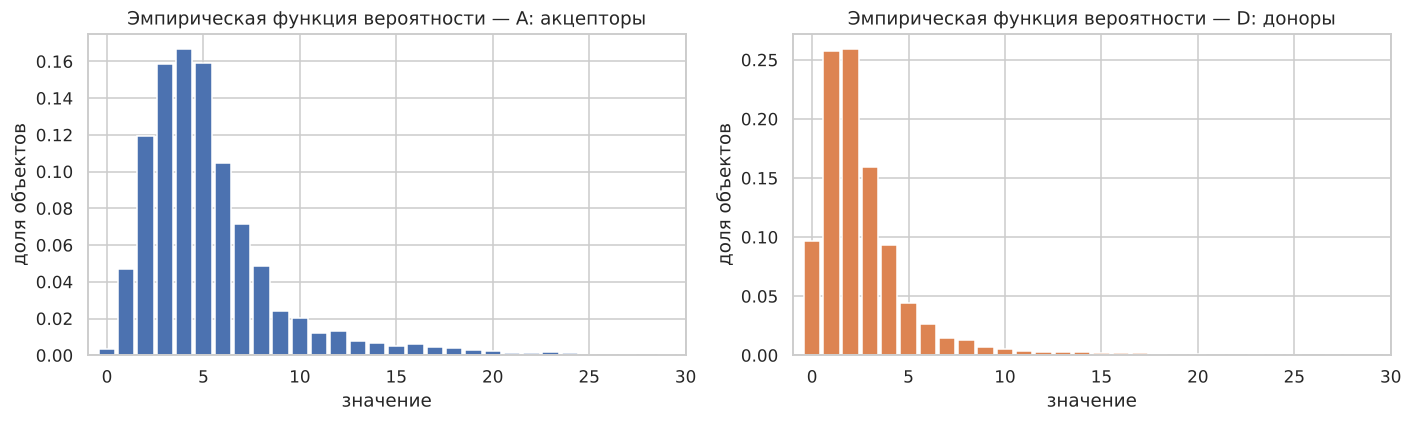

,A,D
среднее,5.428,2.738
медиана,5.000,2.000
дисперсия,18.588,9.901


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, x, name, color in zip(axes, (a, d), ("A: акцепторы", "D: доноры"), ("C0", "C1")):
    vals, cnts = np.unique(x, return_counts=True)
    ax.bar(vals, cnts / N, color=color, width=0.85)
    ax.set_title(f"Эмпирическая функция вероятности — {name}")
    ax.set_xlabel("значение"); ax.set_ylabel("доля объектов")
    ax.set_xlim(-1, 30)
plt.tight_layout()

summary = pd.DataFrame({
    "A": [a.mean(), np.median(a), a.var(ddof=0)],
    "D": [d.mean(), np.median(d), d.var(ddof=0)],
}, index=["среднее", "медиана", "дисперсия"]).round(3)
summary

## 2. Зависимость между A и D

Корреляционной матрицы недостаточно: коэффициент Пирсона измеряет только **линейную** связь и чувствителен к выбросам. Поэтому проверяем независимость несколькими способами:

1. три коэффициента — Пирсон, Спирмен, Кендалл (устойчивые к форме связи ранговые);
2. критерий $\chi^2$ для таблицы сопряжённости (значения усечены сверху, чтобы ячейки не были пустыми);
3. перестановочный тест для коэффициента Спирмена — не требует предположений о распределении.

**Гипотезы:** $H_0$: A и D независимы; $H_1$: между A и D есть статистическая зависимость. Уровень значимости $\alpha = 0{,}05$.

In [3]:
# --- коэффициенты связи
mask_core = (a <= np.percentile(a, 99)) & (d <= np.percentile(d, 99))   # без верхнего 1% по каждой величине

pearson = stats.pearsonr(a, d)
spearman = stats.spearmanr(a, d)
kendall = stats.kendalltau(a, d)
pearson_core = stats.pearsonr(a[mask_core], d[mask_core])
pearson_log = stats.pearsonr(np.log1p(a), np.log1p(d))

coef_table = pd.DataFrame({
    "коэффициент": [pearson.statistic, spearman.statistic, kendall.statistic,
                    pearson_core.statistic, pearson_log.statistic],
}, index=["Пирсон (все данные)", "Спирмен", "Кендалл τ",
          "Пирсон без верхнего 1%", "Пирсон для log(1+x)"]).round(3)

# --- критерий хи-квадрат для таблицы сопряжённости
A_CLIP, D_CLIP = 10, 6
ct = pd.crosstab(np.minimum(a, A_CLIP), np.minimum(d, D_CLIP))
chi2, p_chi2, dof, expected = stats.chi2_contingency(ct)
cramers_v = np.sqrt(chi2 / (N * (min(ct.shape) - 1)))

# --- перестановочный тест для Спирмена
def spearman_permutation(x, y, n_perm=5000):
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    observed = np.corrcoef(rx, ry)[0, 1]
    null = np.array([np.corrcoef(rx, RNG.permutation(ry))[0, 1] for _ in range(n_perm)])
    p_value = (1 + np.sum(np.abs(null) >= abs(observed))) / (n_perm + 1)
    return observed, null, p_value

rho_obs, rho_null, p_perm = spearman_permutation(a, d)

print(f"Таблица сопряжённости: {ct.shape[0]}x{ct.shape[1]}, минимальное ожидаемое число в ячейке = {expected.min():.2f}, "
      f"доля ячеек с ожидаемым числом < 5: {(expected < 5).mean():.1%}")
print(f"chi2 = {chi2:.1f}, степеней свободы = {dof}, p = {fmt_p(p_chi2)}, V Крамера = {cramers_v:.3f}")
print(f"Перестановочный тест (Спирмен): rho = {rho_obs:.3f}; при независимости rho ≈ 0 ± {rho_null.std():.4f} "
      f"(максимум |rho| среди перестановок {np.abs(rho_null).max():.3f})")
print(f"p = {p_perm:.4f} — это минимально возможное значение при 5000 перестановках: ни одна не дала |rho| не меньше наблюдаемого")
coef_table

Таблица сопряжённости: 11x7, минимальное ожидаемое число в ячейке = 1.55, доля ячеек с ожидаемым числом < 5: 5.2%
chi2 = 8627.9, степеней свободы = 60, p = <1e-300, V Крамера = 0.378
Перестановочный тест (Спирмен): rho = 0.646; при независимости rho ≈ 0 ± 0.0099 (максимум |rho| среди перестановок 0.038)
p = 0.0002 — это минимально возможное значение при 5000 перестановках: ни одна не дала |rho| не меньше наблюдаемого


,коэффициент
Пирсон (все данные),0.848
Спирмен,0.646
Кендалл τ,0.537
Пирсон без верхнего 1%,0.769
Пирсон для log(1+x),0.698


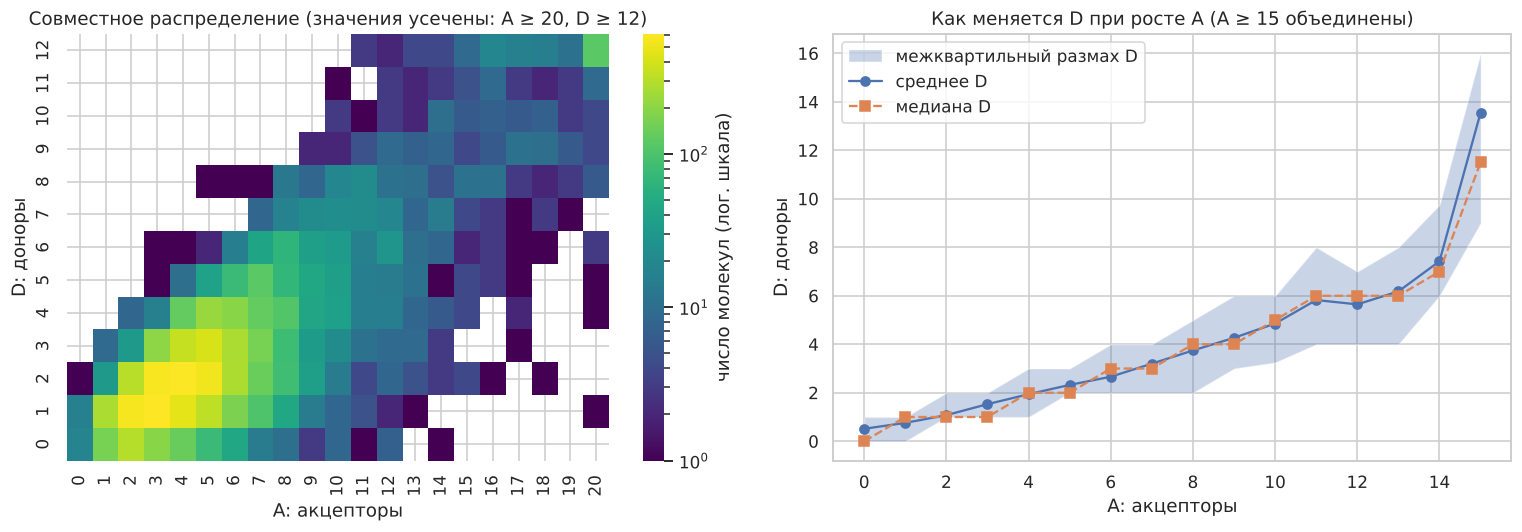

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# совместное распределение (цвет — логарифм числа молекул)
ct_plot = pd.crosstab(np.minimum(d, 12), np.minimum(a, 20)).sort_index(ascending=False)
sns.heatmap(ct_plot.where(ct_plot > 0), norm=LogNorm(), cmap="viridis", ax=axes[0],
            cbar_kws={"label": "число молекул (лог. шкала)"})
axes[0].set_title("Совместное распределение (значения усечены: A ≥ 20, D ≥ 12)")
axes[0].set_xlabel("A: акцепторы"); axes[0].set_ylabel("D: доноры")

# условное распределение D при данном A
cond = (df.assign(a_c=np.minimum(a, 15))
          .groupby("a_c")[D_COL].describe(percentiles=[.25, .5, .75]))
axes[1].fill_between(cond.index, cond["25%"], cond["75%"], alpha=0.3, label="межквартильный размах D")
axes[1].plot(cond.index, cond["mean"], "o-", label="среднее D")
axes[1].plot(cond.index, cond["50%"], "s--", label="медиана D")
axes[1].set_title("Как меняется D при росте A (A ≥ 15 объединены)")
axes[1].set_xlabel("A: акцепторы"); axes[1].set_ylabel("D: доноры")
axes[1].legend()
plt.tight_layout()

**Вывод по этапу 2.**

- **Связь положительная и устойчивая, но корреляция Пирсона её завышает.** Пирсон = 0,85, Спирмен = 0,65, Кендалл = 0,54. Ранговые коэффициенты заметно ниже, потому что на линейную корреляцию сильно влияют крупные молекулы, у которых одновременно очень много и акцепторов, и доноров. Без верхнего 1% значений Пирсон падает до 0,77, после логарифмирования — до 0,70. Для основной массы молекул связь слабее, чем показывает матрица корреляций.
- **Форма связи.** Среднее D растёт с A примерно линейно (порядка 0,4–0,5 донора на один акцептор), а разброс D при этом увеличивается (график справа).
- **Формальная проверка.** $\chi^2$ = 8628 при 60 степенях свободы (p < 10⁻³⁰⁰), V Крамера = 0,38 (связь умеренной силы). Перестановочный тест: при независимости ρ ≈ 0 ± 0,01, наблюдаемое значение 0,65, и ни одна из 5000 перестановок не дала сопоставимого результата (p ≈ 0,0002 — минимум при таком числе перестановок). **$H_0$ о независимости отвергается.**
- Оговорка: молекулы одной базы не идеально независимы друг от друга (много аналогов и однотипных соединений), поэтому крайне малые p-value стоит читать как «связь очень надёжна», а не как точные вероятности.

## 3. Эмпирическая проверка состоятельности оценок

Оценка $\hat\theta_n$ **состоятельна**, если при росте объёма выборки $n$ она по вероятности стремится к истинному значению параметра. Проверяем это экспериментально: для каждого $n$ из сетки делаем $B = 400$ независимых выборок объёма $n$ (из полного набора данных, равновероятно и с возвращением), считаем оценки и смотрим на их разброс вокруг характеристик **полного набора данных**, которые играют роль истинных значений:

- среднее и медиана A, дисперсия A (оценка $S^2$ с $n-1$);
- коэффициент корреляции Пирсона между A и D по выборке.

Для справки: P(A ≤ 4) = 0.4948 (медиана = 5, но доля значений ≤ 4 лишь немного меньше 0,5)
P(|оценка − значение для всего набора| > 5%) и стандартная ошибка среднего


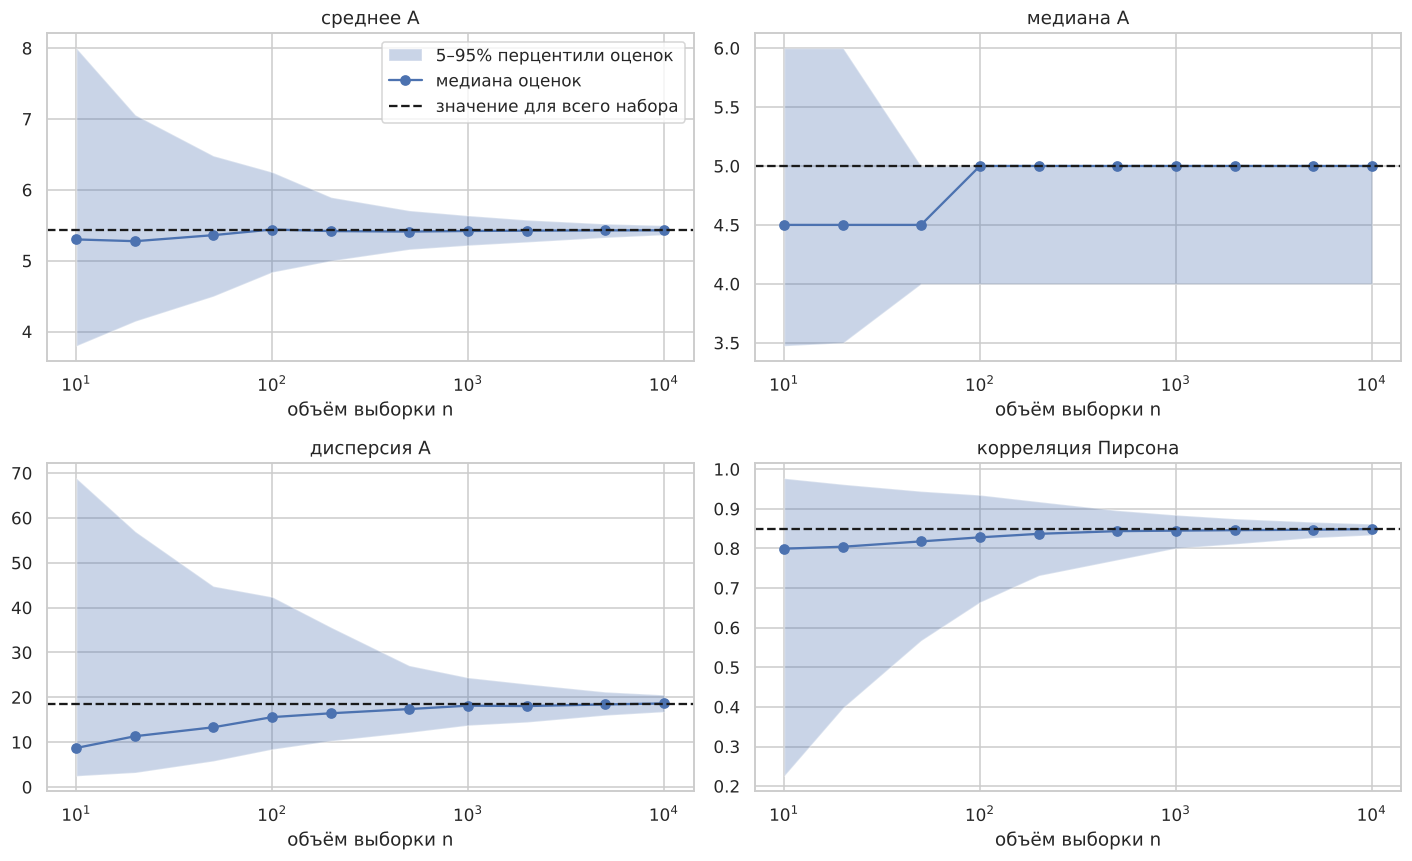

,среднее A,медиана A,дисперсия A,корреляция Пирсона,sd среднего A (эксп.),σ/√n (теор.)
n,,,,,,
10,0.858,0.742,0.980,0.832,1.382,1.363
20,0.808,0.678,0.958,0.745,0.945,0.964
50,0.658,0.528,0.938,0.680,0.599,0.610
100,0.465,0.458,0.920,0.550,0.413,0.431
200,0.372,0.480,0.915,0.408,0.286,0.305
500,0.100,0.422,0.880,0.252,0.175,0.193
1000,0.028,0.410,0.745,0.115,0.128,0.136
2000,0.008,0.325,0.700,0.032,0.099,0.096
5000,0.000,0.225,0.585,0.000,0.061,0.061


In [5]:
SIZES = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, N]
B = 400

def row_pearson(X, Y):
    Xc = X - X.mean(axis=1, keepdims=True)
    Yc = Y - Y.mean(axis=1, keepdims=True)
    return (Xc * Yc).sum(axis=1) / np.sqrt((Xc ** 2).sum(axis=1) * (Yc ** 2).sum(axis=1))

truth = {
    "среднее A": a.mean(),
    "медиана A": np.median(a),
    "дисперсия A": a.var(ddof=0),
    "корреляция Пирсона": np.corrcoef(a, d)[0, 1],
}

est = {k: {} for k in truth}           # k -> n -> массив из B оценок
for n in SIZES:
    idx = RNG.integers(0, N, size=(B, n))
    A_s, D_s = a[idx], d[idx]
    est["среднее A"][n] = A_s.mean(axis=1)
    est["медиана A"][n] = np.median(A_s, axis=1)
    est["дисперсия A"][n] = A_s.var(axis=1, ddof=1)
    est["корреляция Пирсона"][n] = row_pearson(A_s, D_s)

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (name, per_n) in zip(axes.ravel(), est.items()):
    lo = [np.nanpercentile(per_n[n], 5) for n in SIZES]
    hi = [np.nanpercentile(per_n[n], 95) for n in SIZES]
    mid = [np.nanmedian(per_n[n]) for n in SIZES]
    ax.fill_between(SIZES, lo, hi, alpha=0.3, label="5–95% перцентили оценок")
    ax.plot(SIZES, mid, "o-", label="медиана оценок")
    ax.axhline(truth[name], color="k", ls="--", label="значение для всего набора")
    ax.set_xscale("log"); ax.set_title(name); ax.set_xlabel("объём выборки n")
axes[0, 0].legend()
plt.tight_layout()

# вероятность того, что оценка отклонилась от значения для всего набора больше, чем на 5%
rows = []
for n in SIZES:
    row = {"n": n}
    for name, per_n in est.items():
        err = np.abs(per_n[n] - truth[name]) > 0.05 * abs(truth[name])
        row[name] = err.mean()
    row["sd среднего A (эксп.)"] = est["среднее A"][n].std(ddof=1)
    row["σ/√n (теор.)"] = a.std(ddof=0) / np.sqrt(n)
    rows.append(row)
consistency = pd.DataFrame(rows).set_index("n")
print(f"Для справки: P(A ≤ 4) = {(a <= 4).mean():.4f} (медиана = 5, но доля значений ≤ 4 лишь немного меньше 0,5)")
print("P(|оценка − значение для всего набора| > 5%) и стандартная ошибка среднего")
consistency.round(3)

**Вывод по этапу 3.**

- **Среднее и корреляция состоятельны, причём быстро.** Стандартная ошибка среднего A совпадает с теоретической $\sigma/\sqrt{n}$ (0,041 против 0,043 при $n = N$; 1,38 против 1,36 при $n = 10$). Вероятность отклониться от значения для всего набора более чем на 5% падает для среднего с 0,86 ($n = 10$) до 0,10 ($n = 500$), 0,008 ($n = 2000$) и 0 при $n \ge 5000$; для коэффициента корреляции — с 0,83 до 0,25 ($n = 500$) и 0 при $n \ge 5000$.
- **Дисперсия сходится медленно.** Даже при $n = N$ вероятность ошибки больше 5% равна 0,39: хвост очень тяжёлый (эксцесс 33,7), и выборочная дисперсия определяется редкими крупными значениями. Оценка состоятельна, но требует очень больших выборок.
- **Медиана «застревает» из-за дискретности.** Истинная медиана равна 5, но доля значений A ≤ 4 составляет 0,4948, то есть почти 0,5. Поэтому выборочная медиана часто выходит равной 4 или 4,5, и «ошибка» остаётся заметной (0,17 при $n = N$). Это свойство дискретной величины, а не дефект оценки.
- При $n = N$ выборка с возвращением — это не вся база, а бутстреп-выборка, поэтому разброс при $n = N$ не равен нулю.

## 4. EDA и нормализация

Описываем центр, разброс, асимметрию и выбросы, затем подбираем преобразование. Для счётных данных с правым хвостом естественные кандидаты — $\sqrt{x}$ (стабилизирует дисперсию у распределения Пуассона) и $\ln(1+x)$ (ноль допустим). Метод выбираем по тому, насколько он уменьшает асимметрию и эксцесс.

In [6]:
def describe_count(x):
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1
    upper = q3 + 1.5 * iqr
    return pd.Series({
        "min": x.min(), "Q1": q1, "медиана": np.median(x), "среднее": x.mean(), "Q3": q3, "max": x.max(),
        "σ": x.std(ddof=1), "IQR": iqr,
        "асимметрия": stats.skew(x), "экс. эксцесс": stats.kurtosis(x),
        "дисперсия/среднее": x.var(ddof=1) / x.mean(),
        "верх. граница выбросов": upper, "выбросов (>границы)": int((x > upper).sum()),
        "доля выбросов": (x > upper).mean(),
    })

eda = pd.DataFrame({"A": describe_count(a), "D": describe_count(d)}).round(3)
eda

,A,D
min,0.000,0.000
Q1,3.000,1.000
медиана,5.000,2.000
среднее,5.428,2.738
Q3,6.000,3.000
max,79.000,60.000
σ,4.312,3.147
IQR,3.000,2.000
асимметрия,4.157,5.406
экс. эксцесс,33.662,53.651


In [7]:
# самые «тяжёлые» объекты: чем объясняются выбросы
cols = ["drugbank_id", "name", A_COL, D_COL, "cal_molecular_weight"]
df.nlargest(8, A_COL)[cols]

,drugbank_id,name,cal_h_bond_acceptor_count,cal_h_bond_donor_count,cal_molecular_weight
4441,DB05560,Delcasertib,79.0,55.0,2880.310
4314,DB05034,Ularitide,63.0,60.0,3505.926
4809,DB06651,DiaPep 277,60.0,33.0,2390.768
9696,DB15636,Zilucoplan,59.0,28.0,3562.229
9312,DB14806,Avexitide,53.0,45.0,3369.800
9060,DB14027,Taspoglutide,52.0,49.0,3339.763
4634,DB06260,Aviptadil,51.0,48.0,3255.750
9924,DB16187,C-peptide,49.0,41.0,3020.304


In [8]:
# сравнение преобразований по асимметрии и эксцессу
transforms = {
    "исходные": lambda x: x.astype(float),
    "sqrt(x)": np.sqrt,
    "ln(1+x)": np.log1p,
}
rows = []
for name, f in transforms.items():
    for label, x in (("A", a), ("D", d)):
        y = f(x)
        rows.append({"преобразование": name, "величина": label,
                     "асимметрия": stats.skew(y), "экс. эксцесс": stats.kurtosis(y)})
pd.DataFrame(rows).pivot(index="преобразование", columns="величина").round(3)

асимметрия        экс. эксцесс        
величина                A      D            A       D
преобразование                                       
ln(1+x)             0.344  0.339        1.115   0.927
sqrt(x)             1.411  0.872        5.338   4.319
исходные            4.157  5.406       33.662  53.651

z(A): среднее = 0.000, sd = 1.000, асимметрия = 0.344
z(D): среднее = 0.000, sd = 1.000, асимметрия = 0.339


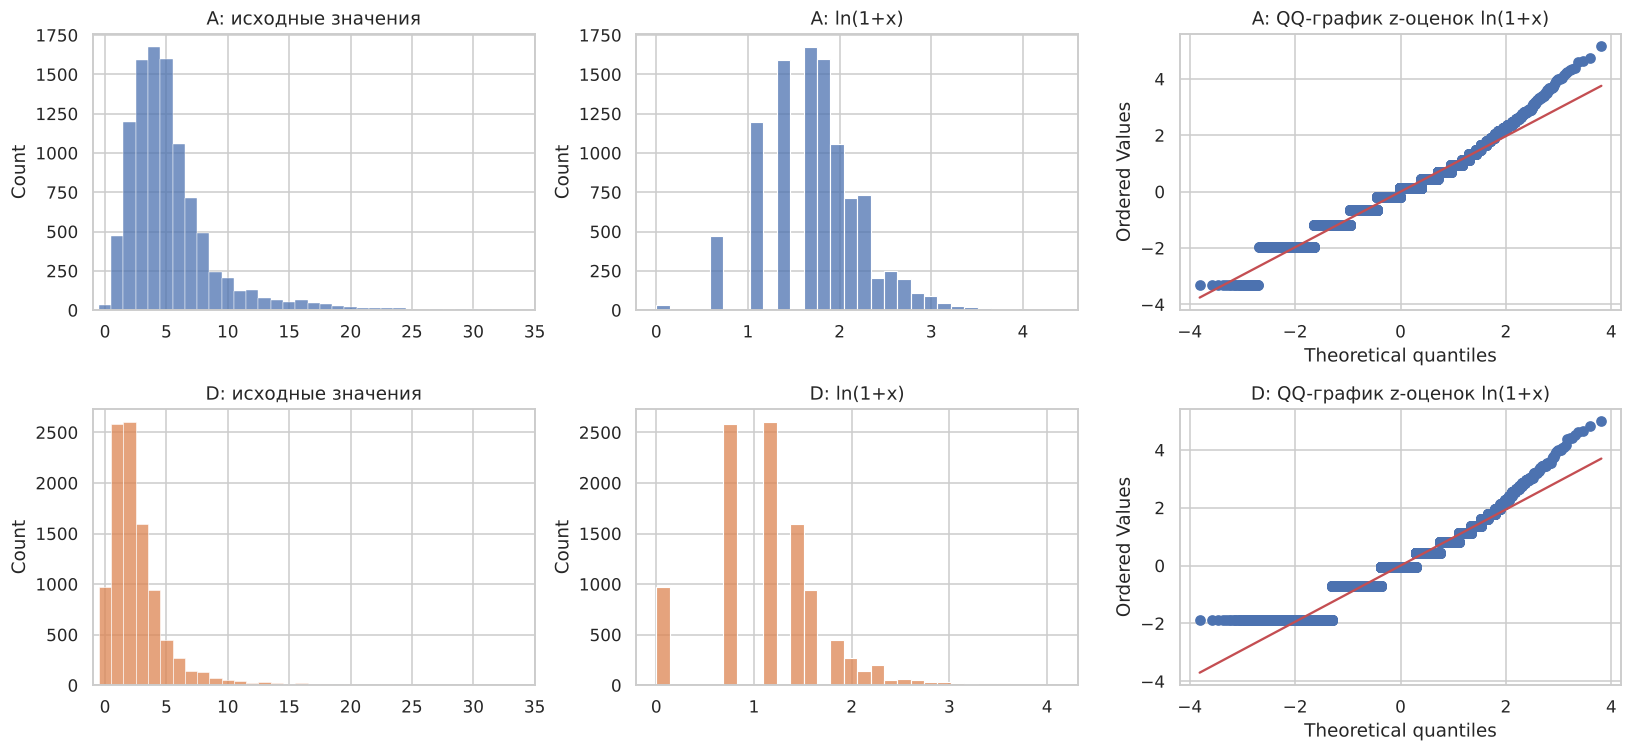

In [9]:
# стандартизация (z-оценка) после логарифмирования
a_log, d_log = np.log1p(a), np.log1p(d)
a_z = (a_log - a_log.mean()) / a_log.std(ddof=1)
d_z = (d_log - d_log.mean()) / d_log.std(ddof=1)
print(f"z(A): среднее = {a_z.mean():.3f}, sd = {a_z.std(ddof=1):.3f}, асимметрия = {stats.skew(a_z):.3f}")
print(f"z(D): среднее = {d_z.mean():.3f}, sd = {d_z.std(ddof=1):.3f}, асимметрия = {stats.skew(d_z):.3f}")

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (x, x_log, z, name) in enumerate(((a, a_log, a_z, "A"), (d, d_log, d_z, "D"))):
    sns.histplot(x, discrete=True, ax=axes[row, 0], color=f"C{row}")
    axes[row, 0].set_title(f"{name}: исходные значения"); axes[row, 0].set_xlim(-1, 35)
    sns.histplot(x_log, bins=30, ax=axes[row, 1], color=f"C{row}")
    axes[row, 1].set_title(f"{name}: ln(1+x)")
    stats.probplot(z, dist="norm", plot=axes[row, 2])
    axes[row, 2].set_title(f"{name}: QQ-график z-оценок ln(1+x)")
plt.tight_layout()

**Вывод по этапу 4.**

- **Распределения резко скошены вправо с тяжёлыми хвостами:** асимметрия 4,2 (A) и 5,4 (D), избыточный эксцесс 33,7 и 53,7. Отношение дисперсии к среднему равно 3,4 и 3,6 — для пуассоновской величины оно было бы близко к 1. По правилу $1{,}5\cdot IQR$ «выбросами» оказываются 767 (7,6%) и 638 (6,4%) молекул.
- **Эти выбросы — не ошибки.** У восьми молекул с наибольшим A молекулярная масса составляет примерно 2400–3600, а доноров — десятки; судя по названиям, это крупные пептиды. Они образуют реальную подгруппу и дают хвост распределения, поэтому удалять их нельзя.
- **Нормализация.** $\ln(1+x)$ работает лучше всего: асимметрия падает до 0,34 для обеих величин, эксцесс — до 1,1 и 0,9. $\sqrt{x}$ слабее (асимметрия 1,41 и 0,87, эксцесс 5,3 и 4,3). Выбрано $\ln(1+x)$ со стандартизацией (проверено: среднее 0, стандартное отклонение 1).
- Нормальными преобразованные величины всё же не стали: на QQ-графиках видны ступени из-за дискретности, а правый хвост остаётся тяжелее нормального. Преобразование уменьшает скошенность, но не превращает счётные данные в непрерывные.

## 5. Выборки с возвращением и без возвращения

Сравниваем два способа отбора при объёмах $n$ от 100 до 9000 ($B = 1000$ повторов). В конечной совокупности объёма $N$ стандартная ошибка выборочного среднего:

- с возвращением: $\sigma/\sqrt{n}$;
- без возвращения: $\dfrac{\sigma}{\sqrt{n}}\sqrt{\dfrac{N-n}{N-1}}$ — поправка на конечную совокупность, при $n = N$ она обнуляет разброс.

Здесь $\sigma$ — стандартное отклонение всех $N$ значений (A).

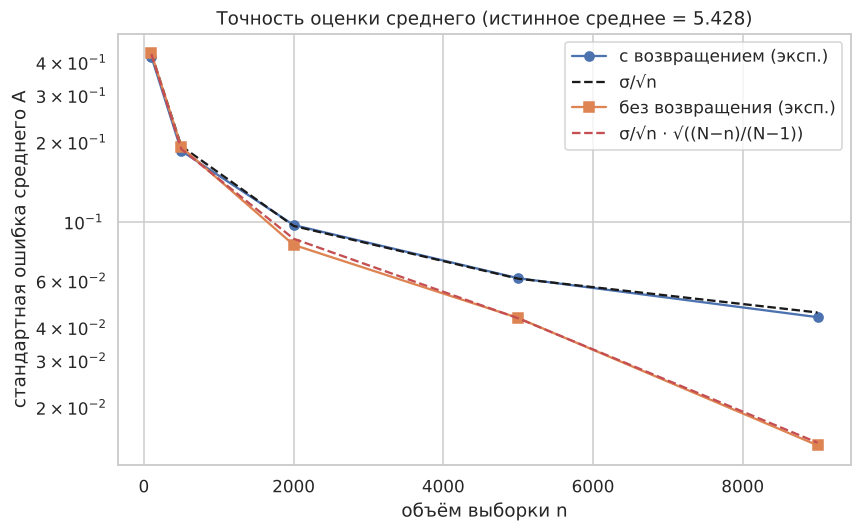

,ср. оценка (с возвр.),ср. оценка (без возвр.),SE эксп. (с возвр.),SE теор. (с возвр.),SE эксп. (без возвр.),SE теор. (без возвр.)
n,,,,,,
100,5.4329,5.4424,0.4198,0.4311,0.4318,0.4290
500,5.4192,5.4344,0.1850,0.1928,0.1913,0.1880
2000,5.4300,5.4299,0.0972,0.0964,0.0818,0.0863
5000,5.4261,5.4279,0.0612,0.0610,0.0433,0.0432
9000,5.4279,5.4283,0.0436,0.0454,0.0143,0.0147


In [10]:
B5 = 1000
SIZES5 = [100, 500, 2000, 5000, 9000]
sigma, mu = a.std(ddof=0), a.mean()

rows = []
for n in SIZES5:
    with_rep = a[RNG.integers(0, N, size=(B5, n))].mean(axis=1)
    without_rep = np.array([a[RNG.choice(N, size=n, replace=False)].mean() for _ in range(B5)])
    rows.append({
        "n": n,
        "ср. оценка (с возвр.)": with_rep.mean(),
        "ср. оценка (без возвр.)": without_rep.mean(),
        "SE эксп. (с возвр.)": with_rep.std(ddof=1),
        "SE теор. (с возвр.)": sigma / np.sqrt(n),
        "SE эксп. (без возвр.)": without_rep.std(ddof=1),
        "SE теор. (без возвр.)": sigma / np.sqrt(n) * np.sqrt((N - n) / (N - 1)),
    })
resampling = pd.DataFrame(rows).set_index("n")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(resampling.index, resampling["SE эксп. (с возвр.)"], "o-", label="с возвращением (эксп.)")
ax.plot(resampling.index, resampling["SE теор. (с возвр.)"], "k--", label="σ/√n")
ax.plot(resampling.index, resampling["SE эксп. (без возвр.)"], "s-", label="без возвращения (эксп.)")
ax.plot(resampling.index, resampling["SE теор. (без возвр.)"], "r--", label="σ/√n · √((N−n)/(N−1))")
ax.set_yscale("log"); ax.set_xlabel("объём выборки n"); ax.set_ylabel("стандартная ошибка среднего A")
ax.set_title(f"Точность оценки среднего (истинное среднее = {mu:.3f})"); ax.legend()
plt.tight_layout()
resampling.round(4)

**Вывод по этапу 5.**

- **Оба способа несмещённые:** средние оценок равны 5,43 в обоих случаях (значение для всей базы 5,428).
- **Точность различается ровно так, как предсказывает теория.** С возвращением стандартная ошибка совпадает с $\sigma/\sqrt{n}$ (0,061 против 0,061 при $n = 5000$). Без возвращения она меньше на множитель $\sqrt{(N-n)/(N-1)}$: при $n = 2000$ — 0,082 против 0,097, при $n = 5000$ — 0,043 против 0,061, при $n = 9000$ — 0,014 против 0,044, то есть втрое меньше (эксперимент 0,0143, теория 0,0147).
- **При $n \ll N$ различия нет:** при $n = 100$ и $n = 500$ оба способа дают практически одинаковую ошибку (0,42 против 0,43 и 0,19 против 0,19), а мелкие расхождения в таблице — шум симуляции.
- Для генератора это значит: выборку с возвращением можно считать набором независимых одинаково распределённых значений; без возвращения значения слабо зависимы, и этим можно пренебречь только при малой доле $n/N$.

## 6. Математическая модель распределения

Для счётной величины естественный первый кандидат — **распределение Пуассона**, у которого дисперсия равна среднему. В данных дисперсия в 3–4 раза больше среднего (см. этап 4), то есть **сверхдисперсия**. Рассматриваем три модели, подбирая параметры методом максимального правдоподобия:

1. **Пуассон** $\text{Pois}(\lambda)$ — 1 параметр;
2. **Отрицательное биномиальное** $\text{NB}(r, p)$ — 2 параметра; это смесь Пуассонов с гамма-распределённым $\lambda$, допускает дисперсию больше среднего;
3. **Смесь Пуассона и NB**: $w\,\text{Pois}(\lambda) + (1-w)\,\text{NB}(r,p)$ — 4 параметра; отражает идею «основная масса обычных молекул плюс хвост крупных».

Модели сравниваем по AIC/BIC и критерию согласия $\chi^2$ Пирсона (интервалы объединяются так, чтобы ожидаемое число в каждом было не меньше 5; число степеней свободы уменьшается на число подобранных параметров).

In [11]:
def to_counts(x):
    vals, cnts = np.unique(x, return_counts=True)
    return vals, cnts

sig = lambda t: 1 / (1 + np.exp(-t))

def pmf_pois(k, lam):          return stats.poisson.pmf(k, lam)
def pmf_nb(k, r, p):           return stats.nbinom.pmf(k, r, p)
def pmf_mix(k, w, lam, r, p):  return w * pmf_pois(k, lam) + (1 - w) * pmf_nb(k, r, p)

def fit_poisson(x):
    return {"lam": x.mean()}

def fit_nb(x):
    vals, cnts = to_counts(x)
    m, v = x.mean(), x.var(ddof=1)
    p0 = min(m / v, 0.99); r0 = m * p0 / (1 - p0)
    nll = lambda th: -(cnts * stats.nbinom.logpmf(vals, np.exp(th[0]), sig(th[1]))).sum()
    res = minimize(nll, [np.log(r0), np.log(p0 / (1 - p0))], method="Nelder-Mead",
                   options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 5000})
    return {"r": np.exp(res.x[0]), "p": sig(res.x[1])}

def fit_mix(x, n_starts=12):
    vals, cnts = to_counts(x)
    m = x.mean()
    def nll(th):
        w, lam, r, p = sig(th[0]), np.exp(th[1]), np.exp(th[2]), sig(th[3])
        pm = pmf_mix(vals, w, lam, r, p)
        return -(cnts * np.log(pm + 1e-300)).sum()
    best = None
    rs = np.random.default_rng(0)
    for _ in range(n_starts):
        th0 = [rs.normal(0, 1), np.log(rs.uniform(0.4, 1.1) * m), np.log(rs.uniform(1, 10)), rs.normal(-1, 1)]
        res = minimize(nll, th0, method="Nelder-Mead", options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 8000})
        if best is None or res.fun < best.fun:
            best = res
    return {"w": sig(best.x[0]), "lam": np.exp(best.x[1]), "r": np.exp(best.x[2]), "p": sig(best.x[3])}

def gof_chi2(x, pmf, n_params, min_expected=5):
    # критерий хи-квадрат Пирсона с объединением интервалов справа налево
    n_obs, kmax = len(x), x.max()
    ks = np.arange(0, kmax + 1)
    probs = pmf(ks)
    probs[-1] += max(1 - probs.sum(), 0)          # масса «хвоста» за пределами наблюдаемого максимума
    obs = np.bincount(x, minlength=kmax + 1)
    exp = probs * n_obs
    o_bins, e_bins, acc_o, acc_e = [], [], 0, 0.0
    for i in range(len(ks) - 1, -1, -1):
        acc_o += obs[i]; acc_e += exp[i]
        if acc_e >= min_expected:
            o_bins.append(acc_o); e_bins.append(acc_e); acc_o, acc_e = 0, 0.0
    if acc_e > 0:
        o_bins[-1] += acc_o; e_bins[-1] += acc_e
    o_bins, e_bins = np.array(o_bins), np.array(e_bins)
    stat = ((o_bins - e_bins) ** 2 / e_bins).sum()
    dof = len(o_bins) - 1 - n_params
    return stat, dof, stats.chi2.sf(stat, dof)

models = {}
rows = []
for label, x in (("A", a), ("D", d)):
    vals, cnts = to_counts(x)
    fits = {
        "Пуассон": (fit_poisson(x), lambda k, q: pmf_pois(k, q["lam"]), 1),
        "NB":      (fit_nb(x),      lambda k, q: pmf_nb(k, q["r"], q["p"]), 2),
        "Пуассон+NB": (fit_mix(x),  lambda k, q: pmf_mix(k, q["w"], q["lam"], q["r"], q["p"]), 4),
    }
    for mname, (par, pmf, kpar) in fits.items():
        ll = (cnts * np.log(pmf(vals, par) + 1e-300)).sum()
        stat, dof, pval = gof_chi2(x, lambda k, par=par, pmf=pmf: pmf(k, par), kpar)
        models[(label, mname)] = (par, pmf)
        rows.append({"величина": label, "модель": mname, "параметров": kpar, "ln L": ll,
                     "AIC": 2 * kpar - 2 * ll, "BIC": kpar * np.log(len(x)) - 2 * ll,
                     "χ²": stat, "ст. своб.": dof, "p-value": pval})

model_table = pd.DataFrame(rows).set_index(["величина", "модель"])
model_view = model_table.round({"ln L": 1, "AIC": 1, "BIC": 1, "χ²": 1})
model_view["p-value"] = model_table["p-value"].map(fmt_p)
model_view["χ²/ст. своб."] = (model_table["χ²"] / model_table["ст. своб."]).round(1)
model_view

параметров     ln L      AIC      BIC       χ²  ст. своб.   p-value  χ²/ст. своб.
величина модель                                                                                       
A        Пуассон              1 -29057.2  58116.5  58123.7  27796.3         14   <1e-300        1985.5
         NB                   2 -25691.7  51387.4  51401.8   2492.0         20   <1e-300         124.6
         Пуассон+NB           4 -24709.5  49427.0  49455.9    180.1         30  2.42e-23           6.0
D        Пуассон              1 -24135.7  48273.5  48280.7  16144.3          9   <1e-300        1793.8
         NB                   2 -21142.9  42289.7  42304.1   2350.8         14   <1e-300         167.9
         Пуассон+NB           4 -20277.9  40563.8  40592.7    146.3         22  2.34e-20           6.7

In [12]:
# где смесь «Пуассон+NB» ещё расходится с данными: ожидаемые и наблюдаемые частоты, стандартизованные остатки
res_tables = {}
for label, x in (("A", a), ("D", d)):
    par, pmf = models[(label, "Пуассон+NB")]
    ks = np.arange(0, 13)
    expd = pmf(ks, par) * N
    obs = np.bincount(x, minlength=13)[:13]
    res_tables[label] = pd.DataFrame({"набл.": obs, "ожид.": expd.round(1),
                                      "ст. остаток": ((obs - expd) / np.sqrt(expd)).round(1)}, index=ks)
pd.concat(res_tables, axis=1)

A                         D                    
   набл.   ожид. ст. остаток набл.   ожид. ст. остаток
0     35   119.4        -7.7   972  1160.9        -5.5
1    471   495.8        -1.1  2583  2355.2         4.7
2   1197  1067.4         4.0  2603  2467.7         2.7
3   1593  1554.2         1.0  1599  1760.9        -3.9
4   1675  1712.5        -0.9   939   977.3        -1.2
5   1600  1523.7         2.0   445   471.0        -1.2
6   1054  1146.3        -2.7   267   226.2         2.7
7    716   758.8        -1.6   145   126.4         1.7
8    489   462.0         1.3   127    87.0         4.3
9    243   274.3        -1.9    74    68.6         0.7
10   206   170.5         2.7    52    57.0        -0.7
11   120   117.6         0.2    40    48.0        -1.2
12   130    90.9         4.1    25    40.5        -2.4

In [13]:
# параметры в понятном виде
rows = []
for (label, mname), (par, _) in models.items():
    if mname == "Пуассон":
        rows.append({"величина": label, "модель": mname, "параметры": f"λ = {par['lam']:.3f}"})
    elif mname == "NB":
        mean = par["r"] * (1 - par["p"]) / par["p"]
        rows.append({"величина": label, "модель": mname,
                     "параметры": f"r = {par['r']:.3f}, p = {par['p']:.3f} (среднее {mean:.3f}, дисперсия {mean / par['p']:.3f})"})
    else:
        mean_nb = par["r"] * (1 - par["p"]) / par["p"]
        rows.append({"величина": label, "модель": mname,
                     "параметры": (f"w = {par['w']:.3f}; компонента 1: Pois(λ = {par['lam']:.3f}); "
                                   f"компонента 2 (вес {1 - par['w']:.3f}): NB с средним {mean_nb:.3f}, r = {par['r']:.3f}")})
pd.set_option("display.max_colwidth", 200)
pd.DataFrame(rows).set_index(["величина", "модель"])

параметры
величина модель                                                                                                        
A        Пуассон                                                                                              λ = 5.428
         NB                                                      r = 4.121, p = 0.432 (среднее 5.428, дисперсия 12.579)
         Пуассон+NB  w = 0.842; компонента 1: Pois(λ = 4.389); компонента 2 (вес 0.158): NB с средним 10.978, r = 3.112
D        Пуассон                                                                                              λ = 2.738
         NB                                                       r = 2.303, p = 0.457 (среднее 2.738, дисперсия 5.992)
         Пуассон+NB   w = 0.858; компонента 1: Pois(λ = 2.094); компонента 2 (вес 0.142): NB с средним 6.631, r = 1.663

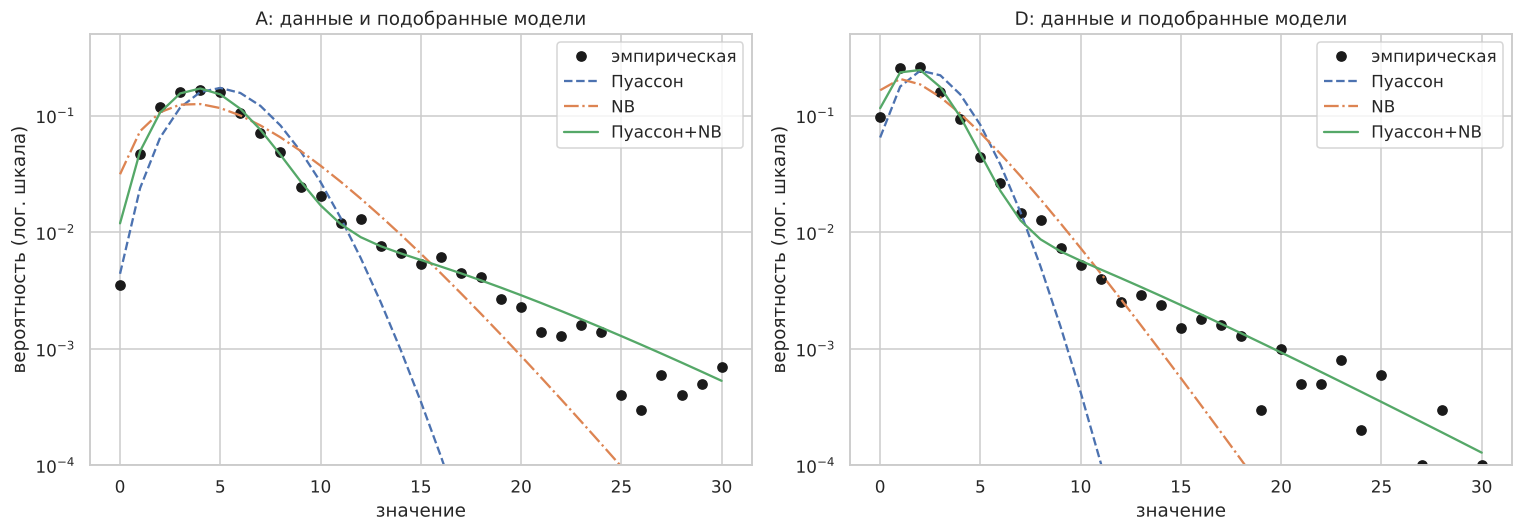

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ks = np.arange(0, 31)
for ax, (label, x) in zip(axes, (("A", a), ("D", d))):
    emp = np.bincount(x, minlength=ks.max() + 1)[:len(ks)] / len(x)
    ax.semilogy(ks, np.where(emp > 0, emp, np.nan), "ko", label="эмпирическая")
    for mname, style in (("Пуассон", "--"), ("NB", "-."), ("Пуассон+NB", "-")):
        par, pmf = models[(label, mname)]
        ax.semilogy(ks, pmf(ks, par), style, label=mname)
    ax.set_ylim(1e-4, 0.5); ax.set_xlabel("значение"); ax.set_ylabel("вероятность (лог. шкала)")
    ax.set_title(f"{label}: данные и подобранные модели"); ax.legend()
plt.tight_layout()

**Вывод по этапу 6.**

- **Пуассон не подходит.** Дисперсия в 3,4–3,6 раза больше среднего, AIC = 58 116 (A) и 48 273 (D) — самые высокие.
- **NB заметно лучше, но форму не воспроизводит.** AIC ниже примерно на 6 700 (A) и 6 000 (D), однако на графике видно, что NB завышает вероятности в районе значений 8–14 и занижает хвост. Лучшим по AIC и BIC оказывается смесь «Пуассон + NB»: ещё на 1 960 (A) и 1 730 (D) ниже, а отношение $\chi^2$ к числу степеней свободы падает со 125 и 168 (NB) до 6,0 и 6,7.
- **Смесь хорошо интерпретируется.** Для A: 84% молекул описываются Pois(4,4), ещё 16% — «тяжёлой» компонентой со средним 11,0. Для D: 86% — Pois(2,1) и 14% — компонента со средним 6,6. Это согласуется с наличием подгруппы крупных молекул, замеченной на этапе 4.
- **Формально смесь тоже отвергается:** $\chi^2$ = 180 при 30 степенях свободы для A и 146 при 22 для D (p ≈ 2·10⁻²³ и 2·10⁻²⁰ соответственно). При 10 000 наблюдений критерий замечает любые небольшие отклонения; по таблице остатков модель завышает долю нулей (A: 35 наблюдаемых против 119 ожидаемых; D: 972 против 1161) и недооценивает значения около 2 для A и около 1 для D.
- **Практически:** смесь «Пуассон + NB» — хорошая рабочая аппроксимация распределения; если нужно точное воспроизведение, можно использовать эмпирическое распределение.

## 7. Проверка исследовательских гипотез

Три гипотезы из `data_review.ipynb`, затрагивающие эти величины. Везде $\alpha = 0{,}05$; при серии однотипных проверок применяется поправка Холма.

### Гипотеза 2 (пара A–D): можно ли заменить одну величину другой?

- $H_0$: A и D независимы; $H_1$: между ними есть зависимость.

Критерии (перестановочный тест Спирмена и $\chi^2$) уже применены на этапе 2. Но значимость зависимости не равна взаимозаменяемости, поэтому дополнительно проверяем **качество предсказания** одной величины по другой (линейная регрессия, 5-кратная кросс-валидация).

In [15]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_predict

def cv_report(x, y):
    pred = cross_val_predict(LinearRegression(), x.reshape(-1, 1), y,
                             cv=KFold(5, shuffle=True, random_state=42))
    base = np.median(y)
    return {
        "R² (кросс-вал.)": 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum(),
        "MAE модели": np.abs(y - pred).mean(),
        "MAE константы (медиана)": np.abs(y - base).mean(),
        "попадание в ±1 (модель)": (np.abs(np.round(pred) - y) <= 1).mean(),
        "попадание в ±1 (константа)": (np.abs(base - y) <= 1).mean(),
    }

pred_table = pd.DataFrame({
    "D → A": cv_report(d, a),
    "A → D": cv_report(a, d),
}).T

print(f"Независимость отвергается: перестановочный тест p = {p_perm:.4f}, chi2-критерий p = {fmt_p(p_chi2)}")
pred_table.round(3)

Независимость отвергается: перестановочный тест p = 0.0002, chi2-критерий p = <1e-300


,R² (кросс-вал.),MAE модели,MAE константы (медиана),попадание в ±1 (модель),попадание в ±1 (константа)
D → A,0.719,1.647,2.521,0.550,0.431
A → D,0.718,1.154,1.639,0.751,0.675


### Гипотеза 1: связано ли отсутствие `state` со значениями A и D?

- $H_0$: распределения A (и D) в группах с пропущенным и известным `state` совпадают.
- $H_1$: распределения различаются.

Критерий Манна–Уитни (данные дискретные, с хвостом). Размер эффекта — ранговая бисериальная корреляция $r_{rb} = 2U/(n_1 n_2) - 1$ (положительна, если в **первой** группе значения в среднем больше).

### Гипотеза 3: различаются ли A и D для групп `cal_rule_of_five` и `cal_bioavailability` (0 и 1)?

- $H_0$: распределение A (или D) не зависит от значения флага; $H_1$: различается.

**Что означает флаг.** Перед интерпретацией проверим, что `cal_rule_of_five` — это правило Липинского (MW ≤ 500, logP ≤ 5, доноров ≤ 5, акцепторов ≤ 10). Если да, то A и D входят в определение флага и различие групп будет частично тавтологическим.

In [16]:
# Что кодирует cal_rule_of_five?
lipinski = ((df["cal_molecular_weight"] <= 500) & (df["cal_logp"] <= 5) & (d <= 5) & (a <= 10)).astype(float)
only_ad = ((d <= 5) & (a <= 10)).astype(float)
print(f"Совпадение флага с полным правилом Липинского:       {(lipinski == df['cal_rule_of_five']).mean():.1%}")
print(f"Совпадение флага с условием только на A и D:          {(only_ad == df['cal_rule_of_five']).mean():.1%}")
g1 = df["cal_rule_of_five"] == 1
print(f"У молекул с флагом 1: max A = {a[g1].max()}, max D = {d[g1].max()}")

Совпадение флага с полным правилом Липинского:       97.1%
Совпадение флага с условием только на A и D:          85.8%
У молекул с флагом 1: max A = 10, max D = 5


In [17]:
def mannwhitney_row(x, mask, label_x, label_group):
    g1, g0 = x[mask], x[~mask]
    res = stats.mannwhitneyu(g1, g0, alternative="two-sided")
    return {"группа (1 vs 0)": label_group, "величина": label_x,
            "n1/n0": f"{len(g1)}/{len(g0)}",
            "медиана 1": np.median(g1), "медиана 0": np.median(g0),
            "r_rb": 2 * res.statistic / (len(g1) * len(g0)) - 1,
            "p (М–У)": res.pvalue,
            "p (КС)": stats.ks_2samp(g1, g0).pvalue}

state_missing = df["state"].isna().to_numpy()
tests = []
for label_x, x in (("A", a), ("D", d)):
    tests.append(mannwhitney_row(x, state_missing, label_x, "state пропущен vs известен"))
    tests.append(mannwhitney_row(x, (df["cal_rule_of_five"] == 1).to_numpy(), label_x, "rule_of_five = 1 vs 0"))
    tests.append(mannwhitney_row(x, (df["cal_bioavailability"] == 1).to_numpy(), label_x, "bioavailability = 1 vs 0"))

tests = pd.DataFrame(tests)

# поправка Холма для всей серии из 6 проверок критерия Манна–Уитни
order = tests["p (М–У)"].argsort().to_numpy()
m = len(tests)
holm = np.empty(m)
running = 0.0
for rank, i in enumerate(order):
    running = max(running, (m - rank) * tests["p (М–У)"].iloc[i])
    holm[i] = min(1.0, running)
tests["p Холма"] = holm
tests["H0 отвергается"] = tests["p Холма"] < ALPHA

tests_view = tests.round({"r_rb": 3})
for col in ("p (М–У)", "p (КС)", "p Холма"):
    tests_view[col] = tests[col].map(fmt_p)
tests_view.set_index(["группа (1 vs 0)", "величина"])

,,n1/n0,медиана 1,медиана 0,r_rb,p (М–У),p (КС),p Холма,H0 отвергается
группа (1 vs 0),величина,,,,,,,,
state пропущен vs известен,A,2346/7700,5.0,4.0,0.129,1.14e-21,3.44e-20,2.29e-21,True
rule_of_five = 1 vs 0,A,7533/2513,4.0,8.0,-0.538,<1e-300,5.71e-321,<1e-300,True
bioavailability = 1 vs 0,A,8497/1549,4.0,10.0,-0.703,<1e-300,4.55e-321,<1e-300,True
state пропущен vs известен,D,2346/7700,2.0,2.0,-0.015,0.2544,2.82e-05,0.2544,False
rule_of_five = 1 vs 0,D,7533/2513,2.0,3.0,-0.362,8.27e-170,4.08e-218,2.48e-169,True
bioavailability = 1 vs 0,D,8497/1549,2.0,5.0,-0.531,3.88e-253,5.76e-256,1.55e-252,True


In [18]:
# Чем отличаются вещества с пропущенным state? (для интерпретации гипотезы 1)
grp = np.where(state_missing, "state пропущен", "state известен")
comparison = pd.DataFrame({
    "n": pd.Series(grp).value_counts(),
    "медиана молекулярной массы": df.groupby(grp)["cal_molecular_weight"].median(),
    "среднее A": df.groupby(grp)[A_COL].mean(),
    "среднее D": df.groupby(grp)[D_COL].mean(),
    "доля D = 0": df.groupby(grp)[D_COL].apply(lambda s: (s == 0).mean()),
    "доля A ≥ 11": df.groupby(grp)[A_COL].apply(lambda s: (s >= 11).mean()),
}).round(3)
comparison

,n,медиана молекулярной массы,среднее A,среднее D,доля D = 0,доля A ≥ 11
state известен,7700,331.380,5.272,2.708,0.110,0.074
state пропущен,2346,402.448,5.942,2.835,0.054,0.083


In [19]:
# Диапазоны значений: как меняется доля молекул с флагом = 1
a_bins = pd.cut(df[A_COL], [-1, 2, 4, 6, 8, 10, np.inf], labels=["0–2", "3–4", "5–6", "7–8", "9–10", "11+"])
d_bins = pd.cut(df[D_COL], [-1, 0, 1, 2, 3, 4, 5, np.inf], labels=["0", "1", "2", "3", "4", "5", "6+"])

flags = ["cal_rule_of_five", "cal_bioavailability"]
by_a = df.groupby(a_bins, observed=True)[flags].mean().assign(n=a_bins.value_counts().sort_index())
by_d = df.groupby(d_bins, observed=True)[flags].mean().assign(n=d_bins.value_counts().sort_index())
by_a.index.name, by_d.index.name = "A (акцепторы)", "D (доноры)"
print("Доля молекул с флагом = 1 по диапазонам A"); print(by_a.round(3).to_string())
print(); print("Доля молекул с флагом = 1 по диапазонам D"); print(by_d.round(3).to_string())

Доля молекул с флагом = 1 по диапазонам A
               cal_rule_of_five  cal_bioavailability     n
A (акцепторы)                                             
0–2                       0.854                0.959  1703
3–4                       0.885                0.952  3268
5–6                       0.850                0.929  2654
7–8                       0.642                0.826  1205
9–10                      0.350                0.630   449
11+                       0.000                0.012   767

Доля молекул с флагом = 1 по диапазонам D
            cal_rule_of_five  cal_bioavailability     n
D (доноры)                                             
0                      0.779                0.906   972
1                      0.841                0.933  2583
2                      0.831                0.924  2603
3                      0.834                0.917  1599
4                      0.806                0.852   939
5                      0.784                0.825  

**Вывод по этапу 7.**

**Гипотеза 2 (A и D).** $H_0$ о независимости отвергается (этап 2). Предсказательная сила умеренная: кросс-валидированный $R^2$ = 0,72 в обе стороны. Предсказывая A по D, средняя абсолютная ошибка равна 1,65 против 2,52 у тривиального прогноза «всегда медиана»; предсказывая D по A — 1,15 против 1,64. В пределах ±1 от истинного значения попадает 55% против 43% (D → A) и 75% против 68% (A → D). Выигрыш над тривиальным прогнозом есть, но скромный, а $R^2$ в заметной мере обеспечен крупными молекулами (без верхнего 1% корреляция 0,77, то есть $R^2 \approx 0{,}59$). **Величины связаны, но одну нельзя заменять другой без заметной потери информации**: ошибка в 1–2 центра на молекулу велика при медианах 5 и 2.

**Гипотеза 1 (пропуски в `state`).** Для A различие есть: медианы 5 против 4, p с поправкой Холма ≈ 2·10⁻²¹, но эффект малый ($r_{rb}$ = 0,13). Для D критерий Манна–Уитни не отвергает $H_0$ (p = 0,25), но критерий Колмогорова–Смирнова (справочно, вне серии Холма) видит различие в форме (p ≈ 3·10⁻⁵): среди молекул без `state` вдвое меньше нулевых D (5,4% против 11,0%). Так как $H_1$ звучит как «различается хотя бы одна характеристика», **$H_0$ отвергается**. Вещества без `state` тяжелее (медианная масса 402 против 331), то есть пропуски не похожи на случайные и связаны с размером молекулы; причинно-следственную связь эти данные установить не позволяют.

**Гипотеза 3 (`cal_rule_of_five`, `cal_bioavailability`).** Все четыре сравнения значимы после поправки Холма (p < 10⁻¹⁶⁰). В группах с флагом 1 значения меньше: медианы A — 4 против 8 (правило пяти) и 4 против 10 (биодоступность), D — 2 против 3 и 2 против 5; размеры эффекта $r_{rb}$ от −0,36 до −0,70. **Но результат в значительной степени тавтологичен:** флаг `cal_rule_of_five` совпадает с правилом Липинского в 97,1% случаев, у молекул с флагом 1 максимальные A и D равны 10 и 5, а при A ≥ 11 или D ≥ 6 доля флага 1 строго равна 0. Доля `cal_bioavailability` = 1 тоже резко падает (до 0,012 при A ≥ 11 и до 0,19 при D ≥ 6), но определение этого флага в датасете не проверялось — как и отмечено в плане, его нужно уточнить до интерпретации. Поэтому значимость не доказывает независимой биологической закономерности: связь частично заложена в самом определении признаков.

## 8. Итог

| Этап | Результат |
|---|---|
| Данные | 10 046 молекул, пропусков нет; A: среднее 5,43, медиана 5; D: среднее 2,74, медиана 2 |
| Зависимость | $H_0$ о независимости отвергается; Пирсон 0,85 завышен хвостом, ранговая связь умеренно сильная (Спирмен 0,65) |
| Оценки | среднее и корреляция состоятельны уже при $n \approx 500$–$5000$; дисперсия и медиана сходятся медленно (тяжёлый хвост, дискретность) |
| Нормализация | выбрано $\ln(1+x)$ со стандартизацией, но нормальности нет; выбросы — реальные крупные пептиды, удалять нельзя |
| Выборки | оба способа несмещённые; без возвращения ошибка меньше на $\sqrt{(N-n)/(N-1)}$, при $n \ll N$ разницы нет |
| Модель | Пуассон и NB не подходят; смесь «Пуассон + NB» лучше всего (84%/16% для A и 86%/14% для D), но формально тоже отвергается при $n \approx 10^4$ |
| Гипотезы | независимость A и D отвергнута, но одну величину другой заменить нельзя ($R^2$ = 0,72); пропуски в `state` не случайны (связаны с массой); связь с флагами частично тавтологична |

**Что учесть на следующем этапе (генератор случайной величины).** Генерировать A и D по отдельности и независимо нельзя: связь между ними значима. Разумный вариант — генерировать A из смеси «Пуассон + NB», а D — из условного распределения при заданном A (или моделировать пару совместно). Качество генератора лучше проверять не одним $\chi^2$-критерием, а ещё и сравнением доли нулей и поведения хвоста, где модель сейчас расходится с данными сильнее всего.